<a href="https://colab.research.google.com/github/munnamia1945/AI_ML_DL_CYS_Projects/blob/main/06-feature-engineering-model-selection/feature_engineering_model_selection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 06: Feature Engineering & Model Selection

## Objective
This project demonstrates a complete machine learning workflow with:
- Missing value handling
- Categorical feature encoding
- Numerical feature scaling
- Feature engineering
- Data leakage prevention
- Stratified 5-fold cross-validation
- Model selection and evaluation

## Dataset
Breast Cancer Wisconsin dataset from scikit-learn.

## Models
1. Logistic Regression
2. K-Nearest Neighbors
3. Support Vector Machine
4. Decision Tree
5. Random Forest

## Leakage Prevention
All preprocessing steps are placed inside a scikit-learn Pipeline and
ColumnTransformer. They are fitted only on training data and independently
within each cross-validation fold.

### Cell 2 - Import libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


### Cell 3 - Load the dataset

In [ ]:
dataset = load_breast_cancer(as_frame=True)

df = dataset.data.copy()

# Target: 1 = malignant, 0 = benign
df["target"] = (dataset.target == 0).astype(int)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
print("Original features:", dataset.data.shape[1])
print("\nTarget distribution:")
print(df["target"].value_counts().rename(index={
    0: "Benign",
    1: "Malignant"
}))

Dataset loaded successfully.
Dataset shape: (569, 31)
Original features: 30

Target distribution:
target
Benign       357
Malignant    212
Name: count, dtype: int64


### Cell 4 - Explore the dataset

In [ ]:
print("First five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe().T)

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoo

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


### Cell 5 - Check target distribution

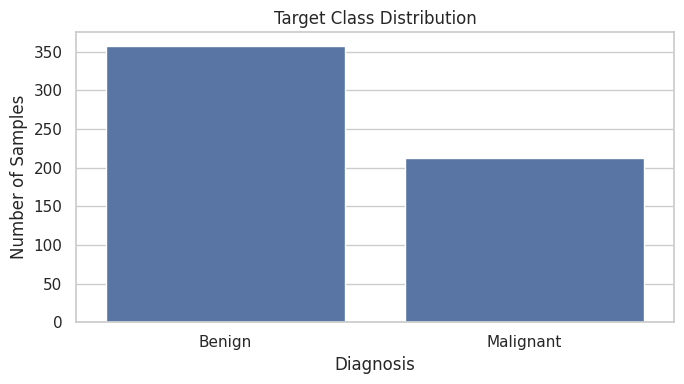

In [ ]:
target_counts = df["target"].map({
    0: "Benign",
    1: "Malignant"
}).value_counts()

plt.figure(figsize=(7, 4))
sns.barplot(x=target_counts.index, y=target_counts.values)
plt.title("Target Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

## Cell 6 - Feature engineering and demonstration missing values

The dataset contains numerical features, so we added a numerical feature (radius_texture_ratio) and a categorical feature (radius_group). We also simulated missing values to practice preprocessing; these were not present in the original dataset

In [ ]:
work_df = df.copy()

# Numerical feature engineering
work_df["radius_texture_ratio"] = (
    work_df["mean radius"] /
    (work_df["mean texture"] + 1e-8)
)

# Categorical feature derived from mean radius
work_df["radius_group"] = pd.cut(
    work_df["mean radius"],
    bins=[-np.inf, 15, 20, np.inf],
    labels=["Small", "Medium", "Large"]
).astype("object")

# Simulate missing values for learning purposes
rng = np.random.default_rng(RANDOM_STATE)

numeric_missing_columns = [
    "mean texture",
    "mean smoothness",
    "radius_texture_ratio"
]

for column in numeric_missing_columns:
    missing_indices = rng.choice(
        work_df.index,
        size=int(0.03 * len(work_df)),
        replace=False
    )
    work_df.loc[missing_indices, column] = np.nan

categorical_missing_indices = rng.choice(
    work_df.index,
    size=int(0.05 * len(work_df)),
    replace=False
)

work_df.loc[categorical_missing_indices, "radius_group"] = np.nan

print("Feature engineering completed.")
print("New dataset shape:", work_df.shape)
print("\nMissing values added for demonstration.")

Feature engineering completed.
New dataset shape: (569, 33)

Missing values added for demonstration.


### Cell 7 - Analyze missing values

,Missing Count,Missing Percentage
radius_group,28,4.92
mean texture,17,2.99
mean smoothness,17,2.99
radius_texture_ratio,17,2.99


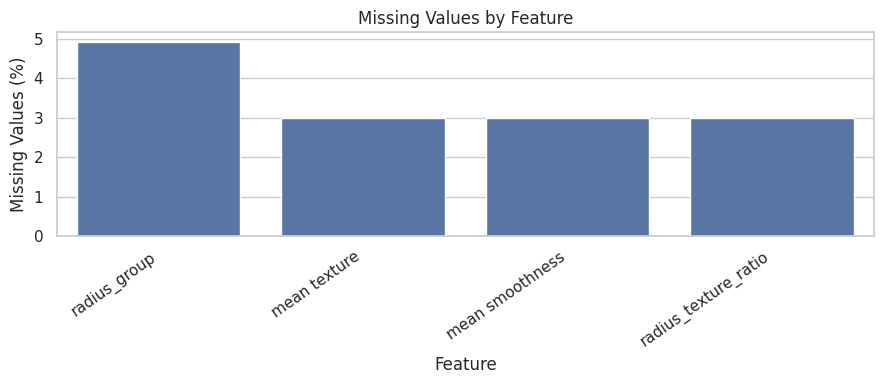

In [ ]:
missing_summary = pd.DataFrame({
    "Missing Count": work_df.isnull().sum(),
    "Missing Percentage": (
        work_df.isnull().mean() * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing Percentage", ascending=False)

display(missing_summary)

if not missing_summary.empty:
    plt.figure(figsize=(9, 4))
    sns.barplot(
        x=missing_summary.index,
        y=missing_summary["Missing Percentage"]
    )
    plt.title("Missing Values by Feature")
    plt.ylabel("Missing Values (%)")
    plt.xlabel("Feature")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

### Cell 8 - Separate features and target

In [ ]:
X = work_df.drop(columns=["target"])
y = work_df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget labels:")
print("0 = Benign")
print("1 = Malignant")

print("\nCategorical features:")
print(X.select_dtypes(
    include=["object", "category"]
).columns.tolist())

print("\nNumerical feature count:",
      len(X.select_dtypes(include=np.number).columns))

Features shape: (569, 32)
Target shape: (569,)

Target labels:
0 = Benign
1 = Malignant

Categorical features:
['radius_group']

Numerical feature count: 31


### Cell 9 - Train-test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training samples: 455
Testing samples: 114

Training target distribution:
target
0    0.626
1    0.374
Name: proportion, dtype: float64

Testing target distribution:
target
0    0.632
1    0.368
Name: proportion, dtype: float64


### Cell 10 - Identify numerical and categorical columns

In [ ]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical feature count:", len(numeric_features))
print("Categorical feature count:", len(categorical_features))

print("\nCategorical columns:", categorical_features)

Numerical feature count: 31
Categorical feature count: 1

Categorical columns: ['radius_group']


### Cell 11 - Build preprocessing pipelines
We used median imputation and scaling for numerical features, and most-frequent imputation and one-hot encoding for categorical features

In [ ]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


### Cell 12 - Define candidate models

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Support Vector Machine": SVC(
        probability=True,
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

print("Number of candidate models:", len(models))
for model_name in models:
    print("-", model_name)

Number of candidate models: 5
- Logistic Regression
- K-Nearest Neighbors
- Support Vector Machine
- Decision Tree
- Random Forest


## Cell 13 - Configure 5-fold cross-validation
We used StratifiedKFold to maintain class proportions across folds. Cross-validation was performed only on the training data.

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

print("Cross-validation: 5 stratified folds")
print("Primary model-selection metric: F1-score")

Cross-validation: 5 stratified folds
Primary model-selection metric: F1-score


### Cell 14 — Evaluate all models using cross-validation

Each model uses a single pipeline for preprocessing and training, ensuring that imputers, scalers, and encoders are fitted only on each CV fold’s training portion.

In [ ]:
cv_results = []

for model_name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=-1
    )

    cv_results.append({
        "Model": model_name,
        "CV Accuracy Mean": scores["test_accuracy"].mean(),
        "CV Accuracy Std": scores["test_accuracy"].std(),
        "CV Precision Mean": scores["test_precision"].mean(),
        "CV Recall Mean": scores["test_recall"].mean(),
        "CV F1 Mean": scores["test_f1"].mean(),
        "CV F1 Std": scores["test_f1"].std(),
        "CV ROC-AUC Mean": scores["test_roc_auc"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)
cv_results_df = cv_results_df.sort_values(
    by="CV F1 Mean",
    ascending=False
).reset_index(drop=True)

display(cv_results_df.round(4))

,Model,CV Accuracy Mean,CV Accuracy Std,CV Precision Mean,CV Recall Mean,CV F1 Mean,CV F1 Std,CV ROC-AUC Mean
0,Support Vector Machine,0.9780,0.0098,0.9823,0.9588,0.9700,0.0138,0.9951
1,Logistic Regression,0.9758,0.0108,0.9820,0.9529,0.9671,0.0150,0.9956
2,K-Nearest Neighbors,0.9736,0.0112,0.9882,0.9412,0.9639,0.0151,0.9852
3,Random Forest,0.9604,0.0215,0.9639,0.9294,0.9458,0.0296,0.9879
4,Decision Tree,0.9077,0.0179,0.8847,0.8706,0.8754,0.0241,0.9002


### Cell 15 - Visualize cross-validation results

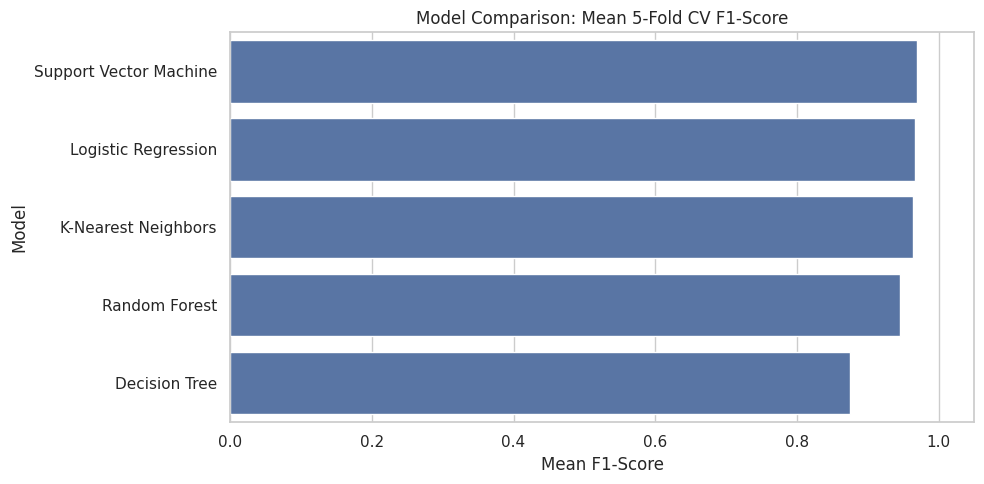

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=cv_results_df,
    x="CV F1 Mean",
    y="Model"
)

plt.title("Model Comparison: Mean 5-Fold CV F1-Score")
plt.xlabel("Mean F1-Score")
plt.ylabel("Model")
plt.xlim(0, 1.05)
plt.tight_layout()
plt.show()

### Cell 16 - Select the best model

In [ ]:
best_model_name = cv_results_df.loc[0, "Model"]
best_model = models[best_model_name]

print("Selected model:", best_model_name)
print("Mean CV F1-score:",
      round(cv_results_df.loc[0, "CV F1 Mean"], 4))

best_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", best_model)
])

# Fit using training data only
best_pipeline.fit(X_train, y_train)

print("\nBest model fitted on training data.")

Selected model: Support Vector Machine
Mean CV F1-score: 0.97

Best model fitted on training data.


### Cell 17 - Final evaluation on the untouched test set

In [ ]:
y_pred = best_pipeline.predict(X_test)

test_metrics = {
    "Model": best_model_name,
    "Test Accuracy": accuracy_score(y_test, y_pred),
    "Test Precision": precision_score(
        y_test, y_pred, zero_division=0
    ),
    "Test Recall": recall_score(
        y_test, y_pred, zero_division=0
    ),
    "Test F1-Score": f1_score(
        y_test, y_pred, zero_division=0
    )
}

# Calculate ROC-AUC when the fitted model supports probabilities
if hasattr(best_pipeline, "predict_proba"):
    y_score = best_pipeline.predict_proba(X_test)[:, 1]
    test_metrics["Test ROC-AUC"] = roc_auc_score(y_test, y_score)
else:
    y_score = best_pipeline.decision_function(X_test)
    test_metrics["Test ROC-AUC"] = roc_auc_score(y_test, y_score)

test_metrics_df = pd.DataFrame([test_metrics])
display(test_metrics_df.round(4))

,Model,Test Accuracy,Test Precision,Test Recall,Test F1-Score,Test ROC-AUC
0,Support Vector Machine,0.9561,0.9744,0.9048,0.9383,0.9917


### Cell 18 - Classification report
Here, class 1 represents malignant and class 0 represents benign.

In [ ]:
print("Classification Report")
print("=" * 60)

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Benign", "Malignant"],
    zero_division=0
))

Classification Report
              precision    recall  f1-score   support

      Benign       0.95      0.99      0.97        72
   Malignant       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



### Cell 19 - Confusion matrixCell 19 — Confusion *matrix*

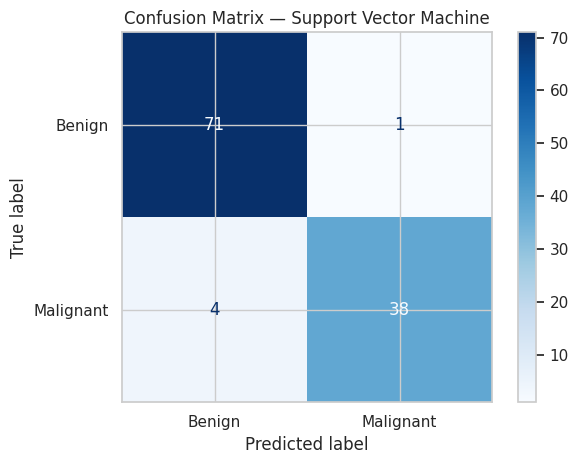

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

### Cell 20 - ROC curve

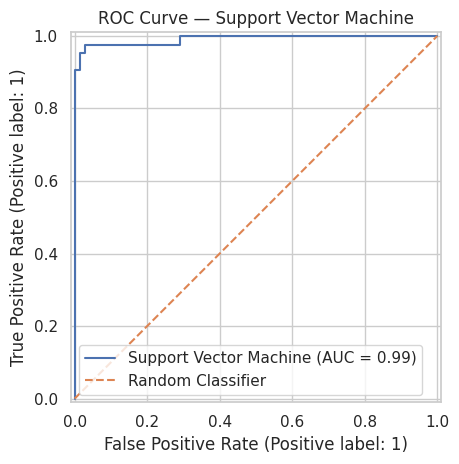

In [ ]:
RocCurveDisplay.from_predictions(
    y_test,
    y_score,
    name=best_model_name
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title(f"ROC Curve — {best_model_name}")
plt.legend()
plt.tight_layout()
plt.show()

### Cell 21 - Verify preprocessing and leakage safeguards

This check verifies that the fitted preprocessing pipeline transforms training features without producing missing or infinite values.

In [ ]:
from scipy import sparse

fitted_preprocessor = best_pipeline.named_steps["preprocessor"]

X_train_transformed = fitted_preprocessor.transform(X_train)

if sparse.issparse(X_train_transformed):
    transformed_values = X_train_transformed.data
else:
    transformed_values = np.asarray(X_train_transformed)

print("Transformed training shape:", X_train_transformed.shape)
print("All transformed values are finite:",
      np.isfinite(transformed_values).all())

print("\nLeakage prevention checklist:")
print("1. Test set separated before model selection.")
print("2. Imputation and scaling are inside the pipeline.")
print("3. Encoding is inside the pipeline.")
print("4. Cross-validation uses training data only.")
print("5. Final evaluation uses the held-out test set.")

Transformed training shape: (455, 34)
All transformed values are finite: True

Leakage prevention checklist:
1. Test set separated before model selection.
2. Imputation and scaling are inside the pipeline.
3. Encoding is inside the pipeline.
4. Cross-validation uses training data only.
5. Final evaluation uses the held-out test set.


### Cell 22 — Export results to CSV

In [ ]:
cv_results_df.to_csv(
    "feature_engineering_cv_results.csv",
    index=False
)

test_metrics_df.to_csv(
    "feature_engineering_test_metrics.csv",
    index=False
)

print("Exported files:")
print("- feature_engineering_cv_results.csv")
print("- feature_engineering_test_metrics.csv")

Exported files:
- feature_engineering_cv_results.csv
- feature_engineering_test_metrics.csv


### Cell 23 — Save the classification report

In [ ]:
report = classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Benign", "Malignant"],
    zero_division=0
)

with open(
    "feature_engineering_classification_report.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(f"Selected Model: {best_model_name}\n\n")
    file.write(report)

print("Classification report saved successfully.")

Classification report saved successfully.


### Cell 24 - Save the trained pipeline (optional)

This saves both the preprocessing steps and the classifier together.


In [ ]:
import joblib

joblib.dump(
    best_pipeline,
    "feature_engineering_best_pipeline.joblib"
)

print("Saved model pipeline:")
print("feature_engineering_best_pipeline.joblib")

Saved model pipeline:
feature_engineering_best_pipeline.joblib


### Cell 25 — Final summary

In [ ]:
print("=" * 65)
print("PROJECT 06: FEATURE ENGINEERING & MODEL SELECTION")
print("=" * 65)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print(f"Candidate models evaluated: {len(models)}")
print(f"Cross-validation folds: {cv.get_n_splits()}")
print(f"Selected model: {best_model_name}")

print("\nTest-set performance:")
for metric, value in test_metrics.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")

print("\nProject completed successfully.")

PROJECT 06: FEATURE ENGINEERING & MODEL SELECTION
Training samples: 455
Testing samples: 114
Candidate models evaluated: 5
Cross-validation folds: 5
Selected model: Support Vector Machine

Test-set performance:
Test Accuracy: 0.9561
Test Precision: 0.9744
Test Recall: 0.9048
Test F1-Score: 0.9383
Test ROC-AUC: 0.9917

Project completed successfully.


### Cell 26 — Conclusion (Markdown cell)

#### Conclusion

This project demonstrated an end-to-end machine learning workflow for
feature engineering and model selection.

#### Key Takeaways
- Missing numerical values were handled using median imputation.
- Missing categorical values were handled using most-frequent imputation.
- Categorical variables were encoded using One-Hot Encoding.
- Numerical features were standardized using StandardScaler.
- Five classification algorithms were compared using stratified 5-fold
  cross-validation.
- The best model was selected using mean cross-validation F1-score.
- Final performance was evaluated on a separate test set.
- Pipelines helped prevent preprocessing leakage between training and
  validation folds.

#### Important Limitation
Missing values were artificially introduced for demonstration because
the original scikit-learn dataset does not contain these simulated
missing entries. The engineered categorical feature was also derived
from an existing numerical feature.

The results therefore demonstrate a methodology, not a claim that this
model is suitable for clinical diagnosis.

#### Future Improvements
- Compare additional models and hyperparameters.
- Use GridSearchCV or RandomizedSearchCV for tuning.
- Evaluate calibration and threshold selection.
- Apply the workflow to other real-world datasets.
- Add reproducibility checks and experiment tracking.